# Phase 1: Dataset Verification & Exploratory Data Analysis (EDA)
## Project: AI-Assisted Code "Silent Regression" Forecaster

### Research Context & Attribution
- **Dataset:** ApacheJIT (A Large Dataset for Just-In-Time Defect Prediction)
- **Authors:** Hossein Keshavarz & Meiyappan Nagappan (University of Waterloo)
- **Publication:** MSR 2022 Data Showcase Track ([arXiv:2203.00101](https://arxiv.org/abs/2203.00101))
- **Official Repository:** [https://github.com/hosseinkshvrz/apachejit](https://github.com/hosseinkshvrz/apachejit)
- **Zenodo Archive:** [https://zenodo.org/records/5907847](https://zenodo.org/records/5907847) (DOI: `10.5281/zenodo.5907847`)
- **License:** Creative Commons Attribution 4.0 International (CC BY 4.0)

### Phase 1 Objective
Inspect the real ApacheJIT dataset, verify schema integrity, check missingness and duplicates, analyze target label distributions and semantics, examine feature characteristics, and identify potential data leakage risks before starting model training.


In [1]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print(f'Pandas version: {pd.__version__}')
print(f'NumPy version: {np.__version__}')


Pandas version: 3.0.1
NumPy version: 2.3.5


In [2]:
data_dir = Path('../data/raw')
if not data_dir.exists():
    data_dir = Path('data/raw')

print(f'Loading datasets from: {data_dir.resolve()}')

df_total = pd.read_csv(data_dir / 'apachejit_total.csv')
df_train = pd.read_csv(data_dir / 'apachejit_train.csv')
df_test_large = pd.read_csv(data_dir / 'apachejit_test_large.csv')
df_test_small = pd.read_csv(data_dir / 'apachejit_test_small.csv')

print('All 4 files loaded successfully!')


Loading datasets from: C:\Users\sanja\Downloads\Data_Analytic_Project\data\raw


All 4 files loaded successfully!


In [3]:
summary_table = pd.DataFrame([
    {'File': 'apachejit_total.csv', 'Rows': df_total.shape[0], 'Cols': df_total.shape[1], 'Memory_MB': round(df_total.memory_usage(deep=True).sum() / (1024**2), 2)},
    {'File': 'apachejit_train.csv', 'Rows': df_train.shape[0], 'Cols': df_train.shape[1], 'Memory_MB': round(df_train.memory_usage(deep=True).sum() / (1024**2), 2)},
    {'File': 'apachejit_test_large.csv', 'Rows': df_test_large.shape[0], 'Cols': df_test_large.shape[1], 'Memory_MB': round(df_test_large.memory_usage(deep=True).sum() / (1024**2), 2)},
    {'File': 'apachejit_test_small.csv', 'Rows': df_test_small.shape[0], 'Cols': df_test_small.shape[1], 'Memory_MB': round(df_test_small.memory_usage(deep=True).sum() / (1024**2), 2)},
])
print(summary_table.to_string(index=False))


                    File   Rows  Cols  Memory_MB
     apachejit_total.csv 106674    18      18.63
     apachejit_train.csv  44834    18       7.84
apachejit_test_large.csv  30111    18       5.24
apachejit_test_small.csv   7526    18       1.31


In [4]:
print('Column Data Types (from df_total):')
types_df = pd.DataFrame({'Column': df_total.columns, 'Dtype': df_total.dtypes.astype(str)}).reset_index(drop=True)
print(types_df.to_string(index=False))

print('\nSample Records (First 5 rows of df_total):')
print(df_total.head(5).to_string())


Column Data Types (from df_total):
     Column   Dtype
  commit_id     str
    project     str
      buggy    bool
        fix    bool
       year   int64
author_date   int64
         la   int64
         ld   int64
         nf   int64
         nd   int64
         ns   int64
        ent float64
       ndev float64
        age float64
        nuc float64
       aexp   int64
      arexp float64
      asexp float64

Sample Records (First 5 rows of df_total):
                                  commit_id        project  buggy    fix  year  author_date   la  ld  nf  nd  ns       ent      ndev       age     nuc  aexp  arexp      asexp
0  7b8480744ea6e6fb41efd4329bb470c8f3c763db  apache/groovy  False  False  2003   1070355653  372  23   8   3   3  2.669743  0.250000  3.625000   2.125   243  243.0   0.683585
1  192b631e7be302ecde822546ba70a9853ddbda01  apache/groovy  False  False  2003   1063298262    2   2   2   2   1  1.000000  1.000000  0.000000   2.500    19   19.0  14.000000
2  0ab6465a7dece

### Feature Taxonomy (Kamei et al., 2013 Framework)
The dataset contains 14 software change metrics categorized into 5 operational dimensions:
1. **Size Dimension:** `la` (lines added), `ld` (lines deleted).
2. **Diffusion Dimension:** `nf` (number of modified files), `nd` (directories), `ns` (subsystems), `ent` (change entropy across files).
3. **Purpose Dimension:** `fix` (boolean flag indicating if the commit addresses a prior bug report).
4. **History Dimension:** `ndev` (number of prior developers), `age` (mean age of modified files), `nuc` (number of unique changes).
5. **Experience Dimension:** `aexp` (author past commit experience), `arexp` (recent experience), `asexp` (subsystem experience).
6. **Metadata & Labels:** `commit_id` (SHA hash), `project` (Apache repo), `year`, `author_date` (Unix timestamp), `buggy` (target).


In [5]:
print('=== Data Completeness & Integrity Audit ===')
files_dict = {
    'total': df_total,
    'train': df_train,
    'test_large': df_test_large,
    'test_small': df_test_small
}

for name, df in files_dict.items():
    total_nulls = df.isna().sum().sum()
    exact_dups = df.duplicated().sum()
    id_dups = df.duplicated(subset=['commit_id']).sum()
    print(f'{name:12s} | Total Missing Values: {total_nulls} | Exact Duplicates: {exact_dups} | Duplicate commit_ids: {id_dups}')

# Schema match verification
print('\nSchema Consistency Check:')
print(f'Train vs Total columns match: {list(df_train.columns) == list(df_total.columns)}')
print(f'Train vs Test_large columns match: {list(df_train.columns) == list(df_test_large.columns)}')


=== Data Completeness & Integrity Audit ===


total        | Total Missing Values: 0 | Exact Duplicates: 0 | Duplicate commit_ids: 0


train        | Total Missing Values: 0 | Exact Duplicates: 0 | Duplicate commit_ids: 0
test_large   | Total Missing Values: 0 | Exact Duplicates: 0 | Duplicate commit_ids: 0
test_small   | Total Missing Values: 0 | Exact Duplicates: 0 | Duplicate commit_ids: 0

Schema Consistency Check:
Train vs Total columns match: True
Train vs Test_large columns match: True


In [6]:
target_summary = []
for name, df in files_dict.items():
    vc = df['buggy'].value_counts()
    pct = df['buggy'].value_counts(normalize=True) * 100
    target_summary.append({
        'Split': name,
        'Buggy (True) Count': int(vc.get(True, 0)),
        'Clean (False) Count': int(vc.get(False, 0)),
        'Buggy %': round(pct.get(True, 0.0), 2),
        'Clean %': round(pct.get(False, 0.0), 2),
        'Imbalance Ratio (Clean : Buggy)': round(vc.get(False, 0) / vc.get(True, 0), 2)
    })

print(pd.DataFrame(target_summary).to_string(index=False))


     Split  Buggy (True) Count  Clean (False) Count  Buggy %  Clean %  Imbalance Ratio (Clean : Buggy)
     total               28239                78435    26.47    73.53                             2.78
     train               22421                22413    50.01    49.99                             1.00
test_large                5818                24293    19.32    80.68                             4.18
test_small                1448                 6078    19.24    80.76                             4.20


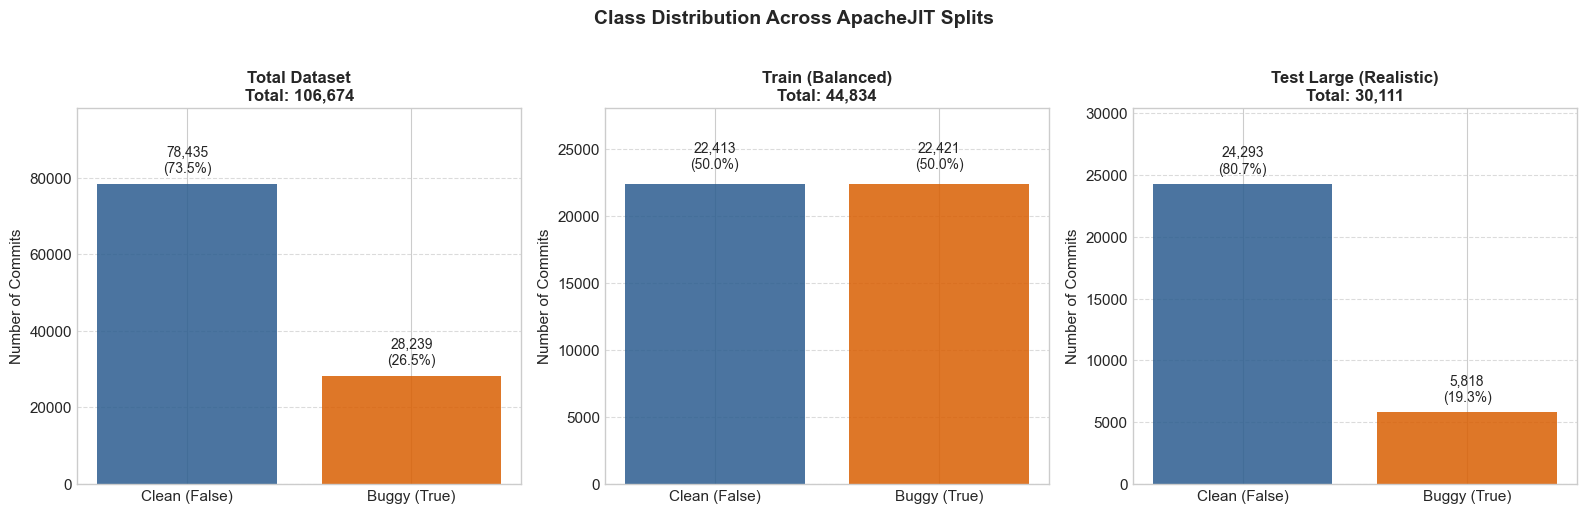

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

splits = [('Total Dataset', df_total), ('Train (Balanced)', df_train), ('Test Large (Realistic)', df_test_large)]

for ax, (title, df) in zip(axes, splits):
    vc = df['buggy'].value_counts()
    pct = df['buggy'].value_counts(normalize=True) * 100
    bars = ax.bar(['Clean (False)', 'Buggy (True)'], [vc.get(False, 0), vc.get(True, 0)], color=['#2b5c8f', '#d95f02'], alpha=0.85)
    ax.set_title(f'{title}\nTotal: {len(df):,}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Number of Commits')
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Annotate counts and percentages
    for bar, p, c in zip(bars, [pct.get(False, 0), pct.get(True, 0)], [vc.get(False, 0), vc.get(True, 0)]):
        yval = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2.0, yval + (len(df)*0.02), f'{c:,}\n({p:.1f}%)', ha='center', va='bottom', fontsize=10)
    ax.set_ylim(0, max(vc) * 1.25)

plt.suptitle('Class Distribution Across ApacheJIT Splits', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### Critical Target Label Analysis: Defect Risk vs. Silent Regressions

#### Research Findings:
1. **Target Semantics:** The `buggy` column indicates whether a commit was identified as **bug-inducing** using the SZZ algorithm (modified code lines were later traced to a bug fix).
2. **Defect Risk vs. Silent Regression:**
   - A **Silent Regression** is a defect that *silently broke pre-existing behavior while existing regression tests passed green*, only causing failure in production or late integration.
   - ApacheJIT contains **no CI/CD execution status**, **no test pass/fail logs**, and **no regression test coverage data**.
   - Therefore, the dataset models **general Just-In-Time Code-Change Defect Risk**, NOT silent regressions specifically.
3. **Scientific Recommendation:**
   - Describe the model accurately as a **Code-Change Defect-Risk Predictor**.
   - Future extensions targeting true silent regressions would require linking CI/CD build logs, unit/regression test outcomes, and production regression issue tags.


In [8]:
numeric_features = ['la', 'ld', 'nf', 'nd', 'ns', 'ent', 'ndev', 'age', 'nuc', 'aexp', 'arexp', 'asexp']
stats_df = df_total[numeric_features].describe().T[['min', '25%', '50%', '75%', 'max', 'mean', 'std']]
stats_df['skewness'] = df_total[numeric_features].skew()
print(stats_df.round(2).to_string())


       min    25%     50%     75%       max     mean      std  skewness
la     0.0   7.00   37.00  147.00   9967.00   189.13   533.16      7.77
ld     0.0   2.00    9.00   41.00   9950.00    76.73   312.68     12.89
nf     1.0   1.00    3.00    7.00    100.00     6.36    10.14      4.13
nd     1.0   1.00    2.00    3.00     89.00     2.94     3.42      4.68
ns     1.0   1.00    1.00    2.00     45.00     1.42     0.98      6.15
ent    0.0   0.00    1.00    2.05      6.57     1.30     1.24      0.93
ndev   0.0   1.00    2.33    5.88    167.50     5.23     9.11      5.80
age    0.0   1.33   13.82   57.00   2713.06    60.33   136.15      5.65
nuc    0.0   5.00   15.00   51.00   3704.50    90.91   251.27      5.60
aexp   0.0  49.00  222.00  829.00  15795.00  1225.43  2704.08      3.32
arexp  0.0  44.50  180.33  609.86   4841.25   606.95  1010.40      2.35
asexp  0.0   1.00   36.00  267.00   7842.00   402.83   991.49      3.93


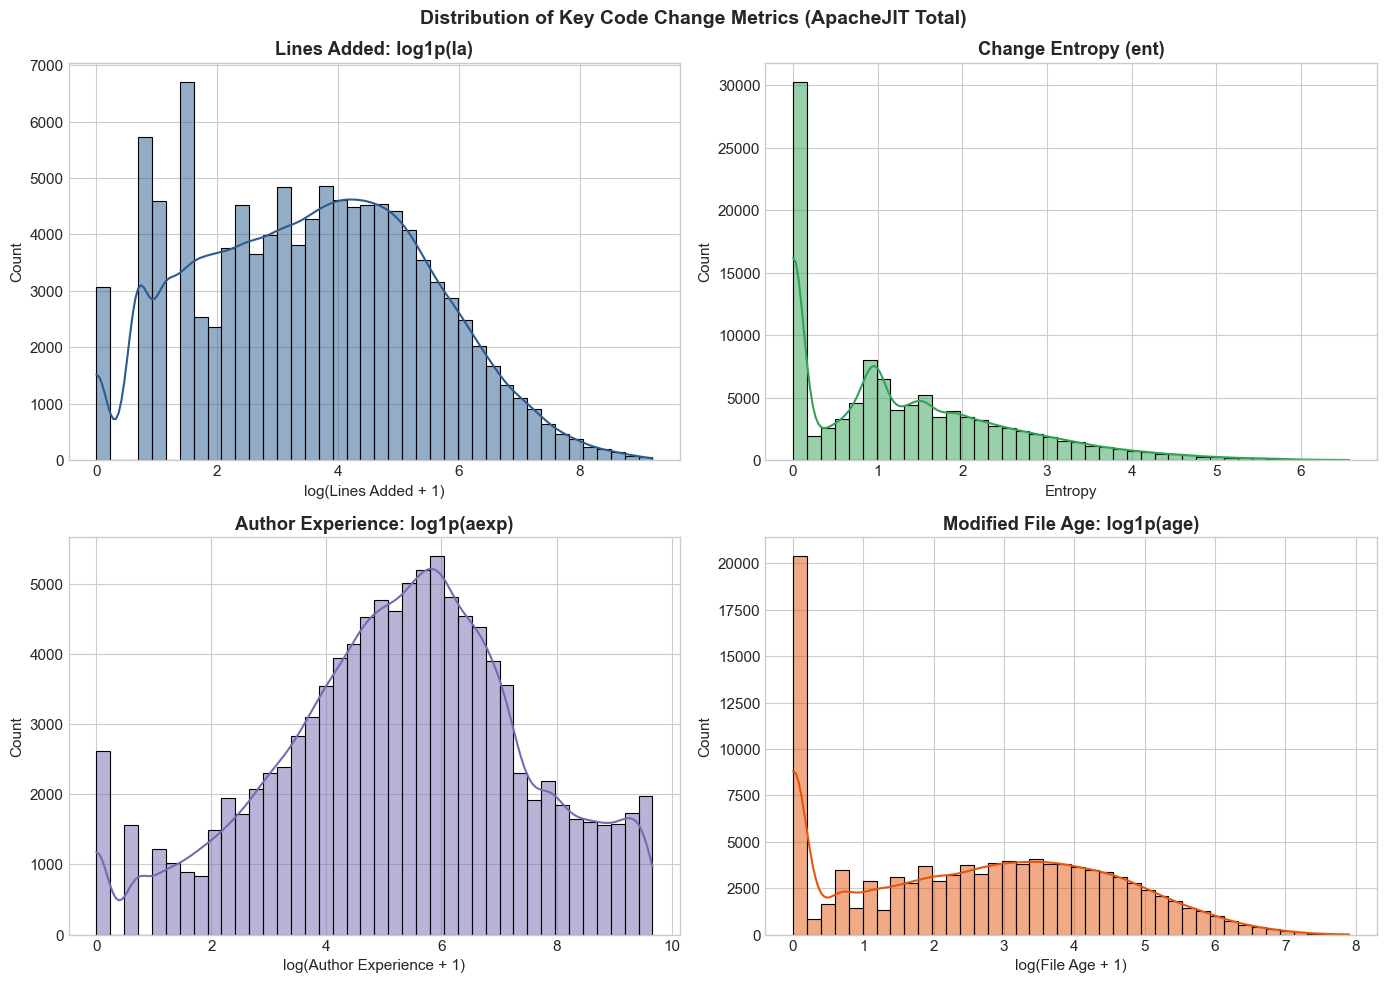

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Lines added (log-transformed)
sns.histplot(np.log1p(df_total['la']), bins=40, kde=True, ax=axes[0, 0], color='#2b5c8f')
axes[0, 0].set_title('Lines Added: log1p(la)', fontweight='bold')
axes[0, 0].set_xlabel('log(Lines Added + 1)')

# Change Entropy
sns.histplot(df_total['ent'], bins=40, kde=True, ax=axes[0, 1], color='#31a354')
axes[0, 1].set_title('Change Entropy (ent)', fontweight='bold')
axes[0, 1].set_xlabel('Entropy')

# Author Experience (log-transformed)
sns.histplot(np.log1p(df_total['aexp']), bins=40, kde=True, ax=axes[1, 0], color='#756bb1')
axes[1, 0].set_title('Author Experience: log1p(aexp)', fontweight='bold')
axes[1, 0].set_xlabel('log(Author Experience + 1)')

# Average File Age (log-transformed)
sns.histplot(np.log1p(df_total['age']), bins=40, kde=True, ax=axes[1, 1], color='#e6550d')
axes[1, 1].set_title('Modified File Age: log1p(age)', fontweight='bold')
axes[1, 1].set_xlabel('log(File Age + 1)')

plt.suptitle('Distribution of Key Code Change Metrics (ApacheJIT Total)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


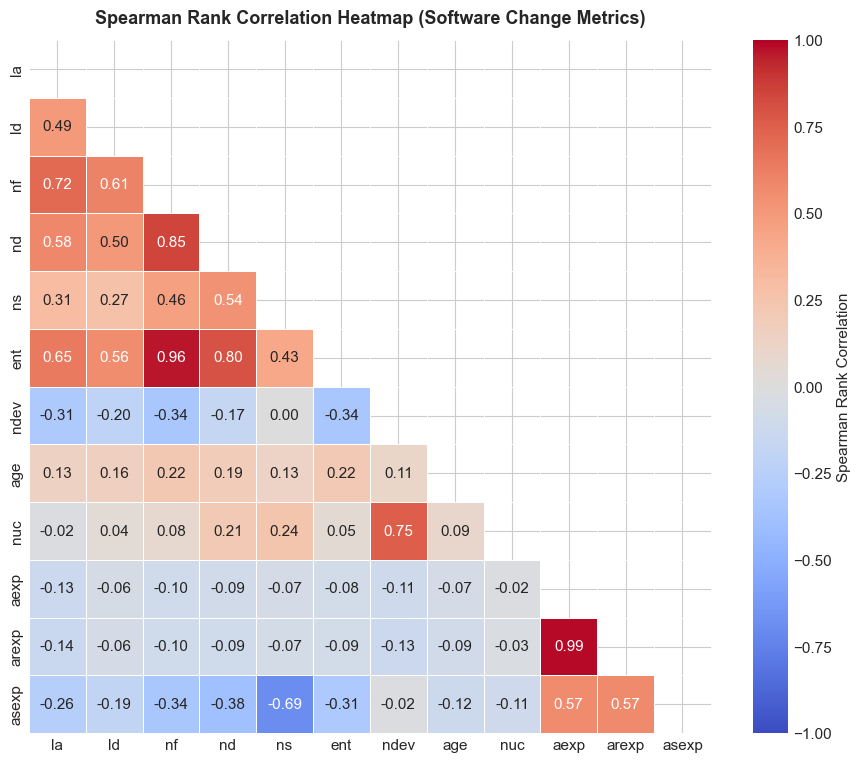

In [10]:
# Using Spearman rank correlation due to extreme skewness in software metrics
plt.figure(figsize=(11, 9))
corr = df_total[numeric_features].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr, 
    mask=mask, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,
    cbar_kws={'label': 'Spearman Rank Correlation'}
)
plt.title('Spearman Rank Correlation Heatmap (Software Change Metrics)', fontsize=13, fontweight='bold', pad=12)
plt.show()


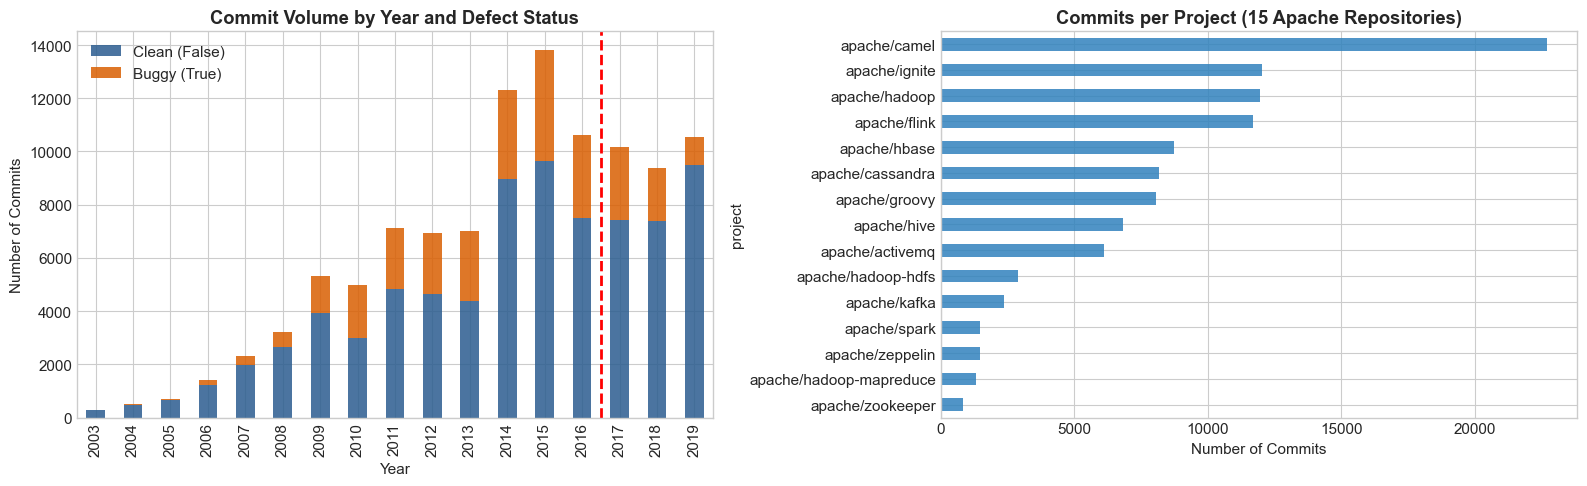

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Commits per Year
year_counts = df_total.groupby(['year', 'buggy']).size().unstack(fill_value=0)
year_counts.plot(kind='bar', stacked=True, ax=axes[0], color=['#2b5c8f', '#d95f02'], alpha=0.85)
axes[0].set_title('Commit Volume by Year and Defect Status', fontweight='bold')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Number of Commits')
axes[0].legend(['Clean (False)', 'Buggy (True)'])
axes[0].axvline(x=13.5, color='red', linestyle='--', linewidth=2, label='Train/Test Split (2016|2017)')

# Commits per Project
project_counts = df_total['project'].value_counts()
project_counts.plot(kind='barh', ax=axes[1], color='#3182bd', alpha=0.85)
axes[1].set_title('Commits per Project (15 Apache Repositories)', fontweight='bold')
axes[1].set_xlabel('Number of Commits')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()


### Phase 1 Conclusions and Recommendations for Phase 2

1. **Zero Missingness:** The ApacheJIT dataset has 106,674 rows with 0 missing cells across all 18 columns. No missing value imputation is necessary.
2. **Evaluation Strategy:**
   - The training set (`apachejit_train.csv`) was artificially balanced by downsampling clean commits.
   - The test set (`apachejit_test_large.csv`) maintains the realistic distribution (~19.3% buggy).
   - Machine learning evaluation must use PR-AUC, ROC-AUC, Brier score, and Cost-Effort metrics (e.g. Recall@Top20%Effort) rather than naive accuracy.
3. **Feature Preprocessing:**
   - Log-transformations (`log1p`) are essential for size and experience metrics due to extreme positive skew.
   - High collinearity exists between `nf`, `nd`, and `ns` (Diffusion dimension), and between `aexp` and `arexp` (Experience dimension).
4. **Data Leakage Safeguards:**
   - `commit_id` must be excluded from feature vectors.
   - `year` and `author_date` should be used strictly for temporal partitioning, not as raw predictor features.
